<img src='../OUTILS/bandeau_MF.png' align='right' width='100%'/>



# <div style='background-color: #1e3c72; color: white; padding: 20px; border-radius: 10px; text-align: center;'>🌍🛰️ Création de composites RGB MTG/FCI avec Satpy</div>

---

## 🎯 Objectifs du TP

- 📦 Utiliser la bibliothèque **Satpy** pour charger des données MTG/FCI
- 🎨 Générer différents **composites RGB** (true color, cloud type, airmass, etc.)
- 🖼️ Visualiser et sauvegarder les images aux formats GeoTIFF, PNG, JPEG
- ✂️ Découper et reprojeter les images sur des zones spécifiques

---

## 📑 Table des matières

| Section | Titre |
|---------|-------|
| 1 | [Prérequis et chargement des librairies](#1-prerequis-et-chargement-des-librairies) |
| 2 | [Configuration des données d’entrée](#2-configuration-des-donnees-dentree) |
| 3 | [Découverte des composites Satpy](#3-decouverte-des-composites-satpy) |
| 4 | [Génération d’un composite RGB](#4-generation-dun-composite-rgb) |
| 5 | [Analyse des trois bandes d’un RGB](#6-analyse-des-trois-bandes-dun-rgb) |
| 6 | [Ajout des frontières politiques](#7-ajout-des-frontieres-politiques) |
| 7 | [Découpe sur une zone géographique](#8-decoupe-sur-une-zone-geographique) |
| 8 | [Reprojection orthographique](#9-reprojection-orthographique) |

---

<div class="alert alert-block alert-warning">
    
### ⚠️ PRÉREQUIS
    
- Le kernel `env_MF_teledetection` doit être actif (contenant `satpy`, `gdal`, `PIL`, etc.).
- Les données MTG utilisées sont des chunks pré-téléchargés. Pour les obtenir, référez-vous au notebook [EUMDAC – téléchargement de données MTG](eumdac.ipynb).
- Le répertoire `/stockage/DATA/20261005/` contient les fichiers d’exemple.
</div>
<hr>

<div class="alert alert-info" role="alert">
    
### 📖 Qu’est-ce que Satpy ?

Satpy est une bibliothèque Python dédiée au traitement des données des satellites météorologiques. Elle permet de :
- Lire de nombreux formats (netCDF, HDF5, etc.) via des **readers**
- Re-échantillonner sur différentes grilles géographiques
- Créer des images monocanal et **composite RGB** (combinaisons de bandes spectrales)
- Appliquer des corrections et améliorations visuelles
- Exporter vers GeoTIFF, PNG, etc.

📚 **Documentation officielle** : [https://satpy.readthedocs.io](https://satpy.readthedocs.io)

</div>

<div class="alert alert-info alert-success">
    
## 1 - Prérequis et chargement des librairies
</div>

In [1]:
from satpy import Scene, find_files_and_readers
from datetime import datetime
import os
import glob
import subprocess
from osgeo import gdal
from PIL import Image
from IPython.display import display
from pyresample import create_area_def

# Configuration des chemins pour GDAL/PROJ (environnement conda)
os.environ['PATH'] = f"/opt/conda/env_MF_teledetection/bin:{os.environ['PATH']}" 
os.environ['PATH'] = f"~/.conda/envs/env_MF_teledetection/bin:{os.environ['PATH']}"
os.environ['GDAL_DATA'] = '/opt/conda/env_MF_teledetection/share/gdal'
os.environ['PROJ_LIB'] = '/opt/conda/env_MF_teledetection/share/proj'

print("✅ Environnement prêt.")

✅ Environnement prêt.


<div class="alert alert-info alert-success">
    
## 2 - Configuration des données d’entrée
</div>

### 📂 Répertoire contenant les chunks MTG (format netCDF)

Les données sont stockées dans `/stockage/DATA/202610051200/`.  
Vous pouvez également utiliser vos propres fichiers téléchargés via EUMDAC.

In [2]:
cd ~/MF_DATA_MANIPULATION

/home/coster/MF_DATA_MANIPULATION


In [3]:
input_dir = "/stockage/DATA/20261005/"
# ❗ Attention : ce chemin doit-être modifié pour toute arborescence différente
work_dir = os.path.expanduser("~/MF_DATA_MANIPULATION")
os.makedirs(work_dir, exist_ok=True)
os.chdir(work_dir)
output_dir = os.path.join(work_dir, "RESULTS")
os.makedirs(output_dir, exist_ok=True)

print(f"📁 Répertoire de travail : {work_dir}")
print(f"📥 Données d’entrée : {input_dir}")
print(f"💾 Sorties : {output_dir}")

📁 Répertoire de travail : /home/coster/MF_DATA_MANIPULATION
📥 Données d’entrée : /stockage/DATA/20261005/
💾 Sorties : /home/coster/MF_DATA_MANIPULATION/RESULTS


### 🔍 Vérification des fichiers disponibles

In [4]:
!ls -lh {input_dir} | head -20

total 1.1G
-rw-r--r--. 1 coster coster 4.7M Oct  5 15:08 W_XX-EUMETSAT-Darmstadt,IMG+SAT,MTI1+FCI-1C-RRAD-FDHSI-FD--CHK-BODY---NC4E_C_EUMT_20261005120402_IDPFI_OPE_20261005120006_20261005120022_N__O_0073_0001.nc
-rw-r--r--. 1 coster coster  13M Oct  5 15:08 W_XX-EUMETSAT-Darmstadt,IMG+SAT,MTI1+FCI-1C-RRAD-FDHSI-FD--CHK-BODY---NC4E_C_EUMT_20261005120416_IDPFI_OPE_20261005120006_20261005120035_N__O_0073_0002.nc
-rw-r--r--. 1 coster coster  18M Oct  5 15:08 W_XX-EUMETSAT-Darmstadt,IMG+SAT,MTI1+FCI-1C-RRAD-FDHSI-FD--CHK-BODY---NC4E_C_EUMT_20261005120431_IDPFI_OPE_20261005120011_20261005120049_N__O_0073_0003.nc
-rw-r--r--. 1 coster coster  21M Oct  5 15:08 W_XX-EUMETSAT-Darmstadt,IMG+SAT,MTI1+FCI-1C-RRAD-FDHSI-FD--CHK-BODY---NC4E_C_EUMT_20261005120438_IDPFI_OPE_20261005120022_20261005120056_N__O_0073_0004.nc
-rw-r--r--. 1 coster coster  24M Oct  5 15:08 W_XX-EUMETSAT-Darmstadt,IMG+SAT,MTI1+FCI-1C-RRAD-FDHSI-FD--CHK-BODY---NC4E_C_EUMT_20261005120448_IDPFI_OPE_20261005120028_20261005120111_N_

<div class="alert alert-info alert-success">
    
## 3 - Lecture des fichiers et découverte des composites Satpy
</div>

### 🕒 Définition de la date et heure de la composite à créer

In [5]:
annee='2026'
mois='10'
jour='05'
heure='12'

yyyy=int(annee)
mm=int(mois)
dd=int(jour)
hh_debut=int(heure)
min_debut=int('00')
hh_fin=int(heure)
min_fin=int('10')

### 📖 Lecteur (reader) pour les données FCI

Satpy utilise le reader `fci_l1c_nc` pour les fichiers NetCDF de MTG/FCI.

Lecture des fichiers

In [6]:
reader_to_use = "fci_l1c_nc"
print(f"📖 Reader utilisé : {reader_to_use}")

myfiles = find_files_and_readers(base_dir=input_dir,
                                 start_time=datetime(yyyy,mm,dd,hh_debut,min_debut),
                                 end_time=datetime(yyyy,mm,dd,hh_fin,min_fin),
                                 reader=reader_to_use)
scn = Scene(filenames=myfiles)
print("✅ Scène Satpy créée.")

📖 Reader utilisé : fci_l1c_nc


sh: line 1: getfattr: command not found
sh: line 1: getfattr: command not found
sh: line 1: getfattr: command not found
sh: line 1: getfattr: command not found
sh: line 1: getfattr: command not found
sh: line 1: getfattr: command not found
sh: line 1: getfattr: command not found
sh: line 1: getfattr: command not found
sh: line 1: getfattr: command not found
sh: line 1: getfattr: command not found
sh: line 1: getfattr: command not found
sh: line 1: getfattr: command not found
sh: line 1: getfattr: command not found
sh: line 1: getfattr: command not found
sh: line 1: getfattr: command not found
sh: line 1: getfattr: command not found
sh: line 1: getfattr: command not found
sh: line 1: getfattr: command not found
sh: line 1: getfattr: command not found
sh: line 1: getfattr: command not found
sh: line 1: getfattr: command not found
sh: line 1: getfattr: command not found
sh: line 1: getfattr: command not found
sh: line 1: getfattr: command not found
sh: line 1: getfattr: command not found


✅ Scène Satpy créée.


**Ne pas tenir compte des avertissements getfaatr**
(Gestion des attributs étendus, non nécessaire ici)

### 📋 Liste des composites RGB disponibles

Satpy propose de nombreux composites prédéfinis pour FCI. Voici les principaux :

In [7]:
all_composites = scn.available_composite_names()
print("🎨 Composites disponibles :\n")
for comp in sorted(all_composites):
    print(f"  - {comp}")

🎨 Composites disponibles :

  - 24h_microphysics
  - airmass
  - ash
  - cimss_cloud_type
  - cimss_cloud_type_raw
  - cloud_phase
  - cloud_phase_distinction
  - cloud_phase_distinction_raw
  - cloud_phase_raw
  - cloud_phase_with_night_ir105
  - cloud_type
  - cloud_type_with_night_ir105
  - cloudtop
  - colorized_ir_clouds
  - convection
  - day_essl_colorized_low_level_moisture
  - day_essl_low_level_moisture
  - day_microphysics
  - day_severe_storms
  - day_severe_storms_tropical
  - dust
  - essl_colorized_low_level_moisture
  - essl_low_level_moisture
  - fci_fire_channels_sum
  - fire_temperature
  - fire_temperature_38refl
  - fire_temperature_rad
  - flames_masked
  - fog
  - geo_color
  - geo_color_background_with_low_clouds
  - geo_color_high_clouds
  - geo_color_low_clouds
  - geo_color_night
  - green_snow
  - hrv_clouds
  - ir108_3d
  - ir_cloud_day
  - ir_sandwich
  - ir_sandwich_with_night_colorized_ir_clouds
  - natural_color
  - natural_color_raw
  - ndvi_hybrid_gre

| Composite | Usage typique |
|-----------|---------------|
| `true_color` | "Vraies couleurs" (jour) |
| `natural_color` | "Variante" de true color |
| `cloud_phase` | Distinction eau/glace |
| `cimss_cloud_type` | Classification nuages |
| `airmass` | Masses d’air (haute troposphère) |
| `ash` | Détection de cendres volcaniques |
| `dust` | Poussières désertiques |
| `fog` | Brouillard et stratus bas (nuit) |
| `night_microphysics` | Microphysique de nuit |
| `convection` | Convection profonde |

📄 **Légendes détaillées** : [Fiches produits MTG - légendes RGB](../DOCS/Fiches_produits_MTG_legendes-RGB.pdf)

### Liste de dataset disponibles

In [8]:
print(scn.available_dataset_names())

['ir_105', 'ir_105_earth_sun_distance', 'ir_105_index_map', 'ir_105_pixel_quality', 'ir_105_platform_altitude', 'ir_105_subsatellite_latitude', 'ir_105_subsatellite_longitude', 'ir_105_subsolar_latitude', 'ir_105_subsolar_longitude', 'ir_105_sun_satellite_distance', 'ir_105_swath_direction', 'ir_105_swath_number', 'ir_105_time', 'ir_123', 'ir_123_earth_sun_distance', 'ir_123_index_map', 'ir_123_pixel_quality', 'ir_123_platform_altitude', 'ir_123_subsatellite_latitude', 'ir_123_subsatellite_longitude', 'ir_123_subsolar_latitude', 'ir_123_subsolar_longitude', 'ir_123_sun_satellite_distance', 'ir_123_swath_direction', 'ir_123_swath_number', 'ir_123_time', 'ir_133', 'ir_133_earth_sun_distance', 'ir_133_index_map', 'ir_133_pixel_quality', 'ir_133_platform_altitude', 'ir_133_subsatellite_latitude', 'ir_133_subsatellite_longitude', 'ir_133_subsolar_latitude', 'ir_133_subsolar_longitude', 'ir_133_sun_satellite_distance', 'ir_133_swath_direction', 'ir_133_swath_number', 'ir_133_time', 'ir_38', 

<div class="alert alert-info alert-success">
    
## 4- Génération d’un composite RGB
</div>

### 🎨 Choix du composite et chargement

Nous allons générer le produit **Cloud Type RGB**. 

La création du tif peut prendre quelques dizaines de secondes (~ 200 Mo pour un plein disque à 1 km soit 11136x11136 pixels)</br>

In [9]:
composite_name = "cimss_cloud_type"   # Modifiez ici pour tester d’autres composites
print(f"🎨 Génération du composite : {composite_name}")

🎨 Génération du composite : cimss_cloud_type


In [10]:
filename = (output_dir + '/RGB_satpy_' + composite_name )
# Chargement du composite (les bandes nécessaires sont automatiquement lues)
scn.load([composite_name], upper_right_corner='NE', generate=False)
print("✅ Composite chargé.")


### Définition de la résolution en 2km (plus rapide pour le Jupyter)
area_def_2km = create_area_def("fci_2km", "+proj=geos +h=35786400 +lon_0=0 +ellps=WGS84", resolution=2000)
scn_resampled = scn.resample(area_def_2km, resampler='nearest') 

#Sauvegarde 
scn_resampled.save_dataset(composite_name, filename=filename + '.tif') 
!gdalinfo {filename}.tif 2>/dev/null | grep -E "Size|Band|Pixel Size|Origin"



✅ Composite chargé.


/home/coster/.conda/envs/env_MF_teledetection/lib/python3.10/site-packages/numpy/lib/_function_base_impl.py:1496: RuntimeWarning: invalid value encountered in subtract
  a = op(a[slice1], a[slice2])
/home/coster/.conda/envs/env_MF_teledetection/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in sin
  return self.func(*new_argspec)
/home/coster/.conda/envs/env_MF_teledetection/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in cos
  return self.func(*new_argspec)
/home/coster/.conda/envs/env_MF_teledetection/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in cos
  return self.func(*new_argspec)
/home/coster/.conda/envs/env_MF_teledetection/lib/python3.10/site-packages/dask/_task_spec.py:759: RuntimeWarning: invalid value encountered in sin
  return self.func(*new_argspec)


Size is 5436, 5418
Origin = (-5436000.000000000000000,5418000.000000000000000)
Pixel Size = (2000.000000000000000,-2000.000000000000000)
Band 1 Block=256x256 Type=Byte, ColorInterp=Red
Band 2 Block=256x256 Type=Byte, ColorInterp=Green
Band 3 Block=256x256 Type=Byte, ColorInterp=Blue
Band 4 Block=256x256 Type=Byte, ColorInterp=Alpha


### ⚠️  Ne pas tenir compte des avertissements

### 🖼️ Redimensionnement et affichage dans le notebook

Using band 4 of source image as alpha.
Creating output file that is 1800P x 1800L.
Processing /home/coster/MF_DATA_MANIPULATION/RESULTS/RGB_satpy_cimss_cloud_type.tif [1/1] : 0...10...20...30...40...50...60...70...80...90...100 - done.


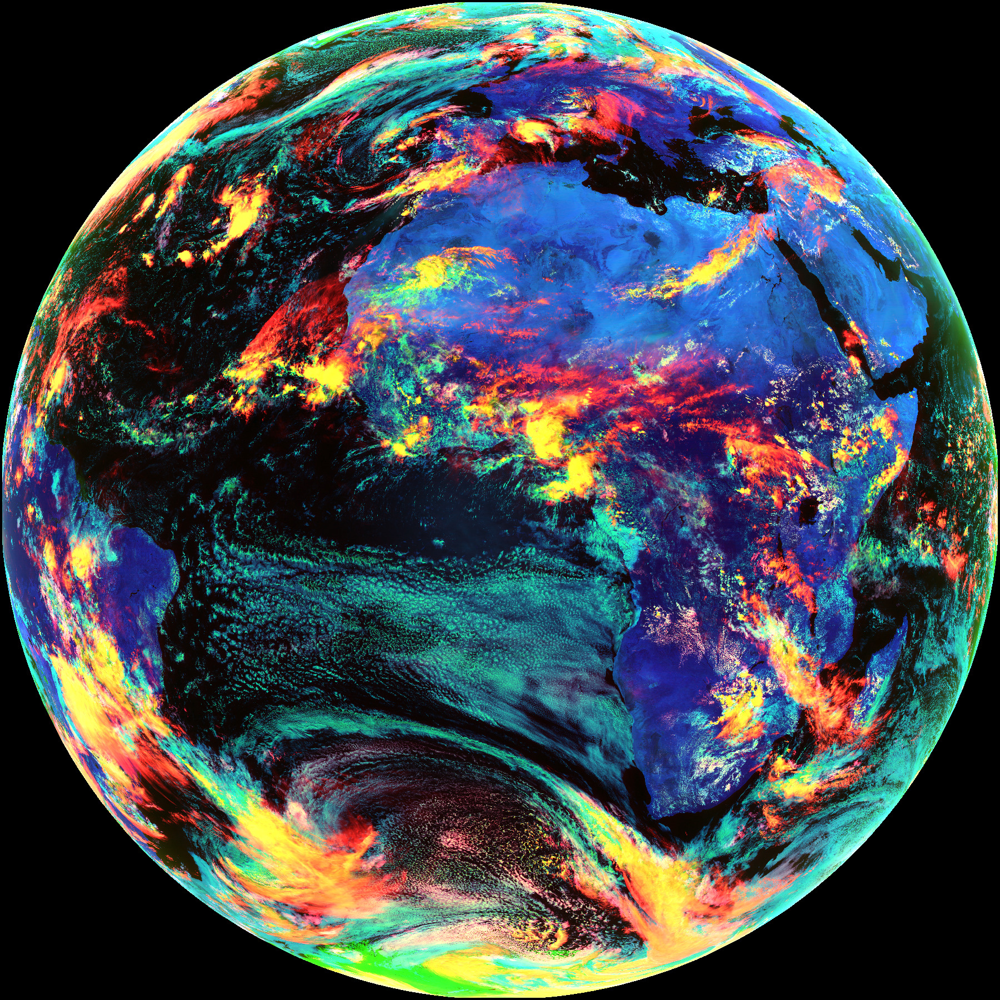

In [12]:
!gdalwarp -overwrite -ts 1800 1800 {filename}.tif {filename}_redim.tif
!convert  {filename}_redim.tif {filename}_redim_HD.jpg > /dev/null 2>&1
!convert -resize 1800 {filename}_redim.tif {filename}_redim.jpg > /dev/null 2>&1
# Affichage
imgredim = Image.open(filename + '_redim.jpg')
display(imgredim)

### 🌍 Bonus : masque circulaire pour ne garder que le disque terrestre


✅ Image avec masque circulaire générée.


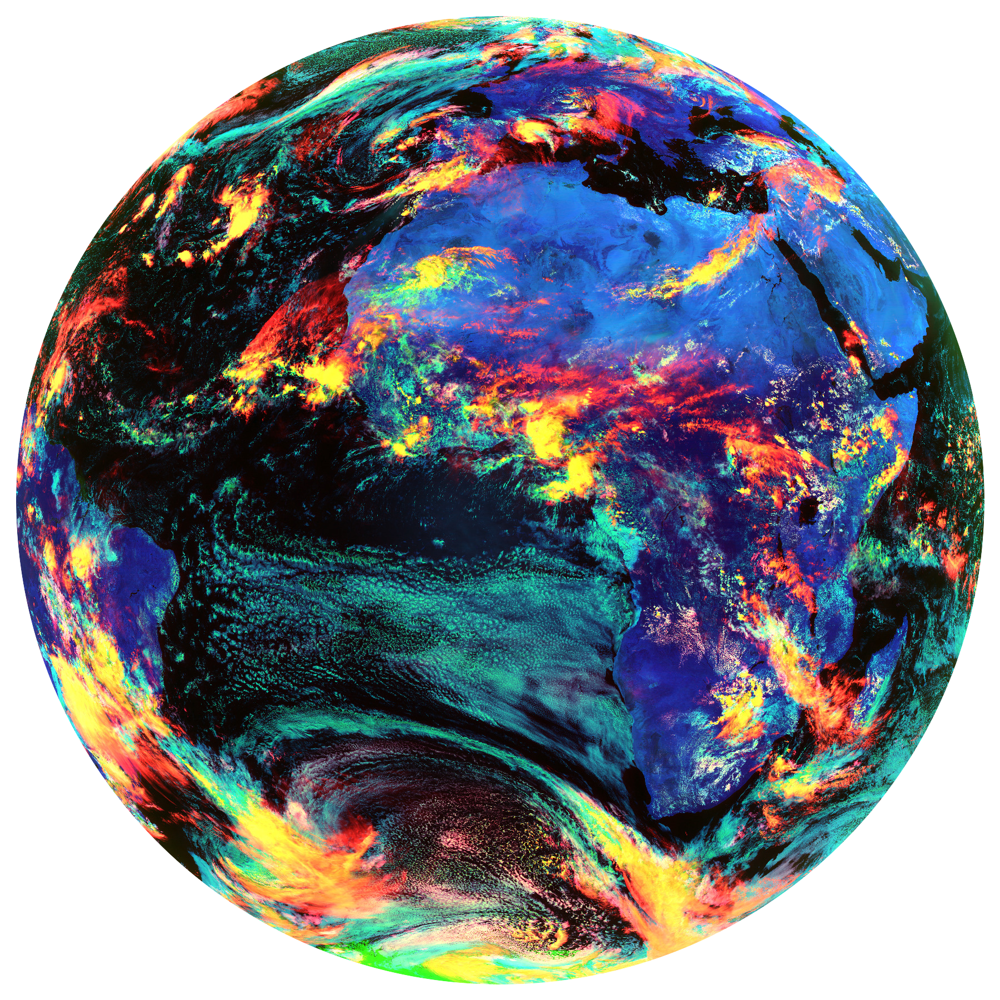

In [13]:
# Création d’un masque circulaire (1800x1800 adapté à la taille du GeoTIFF)
!convert -size 1800x1800 xc:black -fill white -draw "circle 900,900 900,29" mask.png 2>/dev/null

# Application du masque (nécessite une version HD du GeoTIFF)
!convert {filename}_redim_HD.jpg mask.png -alpha off -compose CopyOpacity -composite -alpha on {filename}_redim_HD.png

print("✅ Image avec masque circulaire générée.")
imgredim_png = Image.open(filename + '_redim_HD.png')
display(imgredim_png)

## &emsp;&emsp;&emsp;<a href="../DOCS/mtg_fci_synthese_produits.pdf" target="_blank"><img src='../DOCS/mtg_fci_synthese_produits.jpg' alt='tableau synthèse' width='500px'>  </a>

<div class="alert alert-info alert-success">
    
## 5 - Ajout des frontières politiques
</div>

### 🗺️ Surligner les contours des pays (en rouge) à l’aide de `gdal_rasterize`

In [15]:
!ls OUTILS/boundary/world-administrative-boundaries.shp

OUTILS/boundary/world-administrative-boundaries.shp


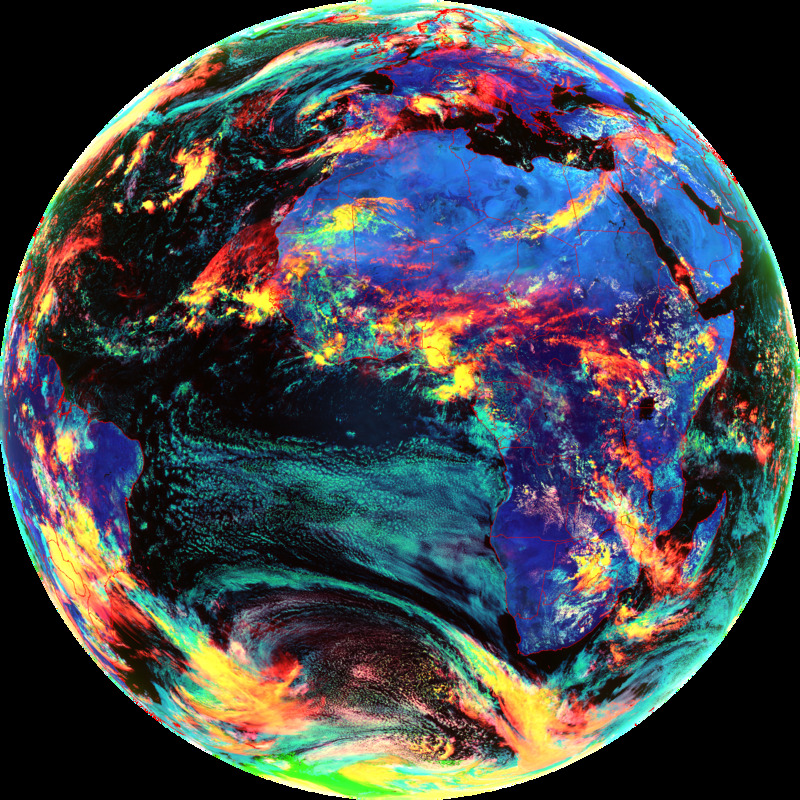

In [16]:
shapefile = "OUTILS/boundary/world-administrative-boundaries.shp"
#!gdal_rasterize -q -b 1 -burn 240 -b 2 -burn 240 -b 3 -burn 240 -l world-administrative-boundaries OUTILS/boundary/world-administrative-boundaries.shp {filename}.tif >/dev/null 2>&1 # frontière blanche
!gdal_rasterize -q -b 1 -burn 255 -b 2 -burn 0 -b 3 -burn 0 -l world-administrative-boundaries OUTILS/boundary/world-administrative-boundaries.shp {filename}_redim.tif >/dev/null 2>&1 # frontière rouge
!convert -resize 800 {filename}_redim.tif {filename}_redim_min.jpg > /dev/null 2>&1
im = Image.open(filename + '_redim_min.jpg')
display(im)

<div class="alert alert-info alert-success">
    
## 6 - Découpe sur une zone géographique
</div>

### ✂️ Définition d’une région d’intérêt (coordonnées WGS84)

Exemple : Espagne (péninsule ibérique) :

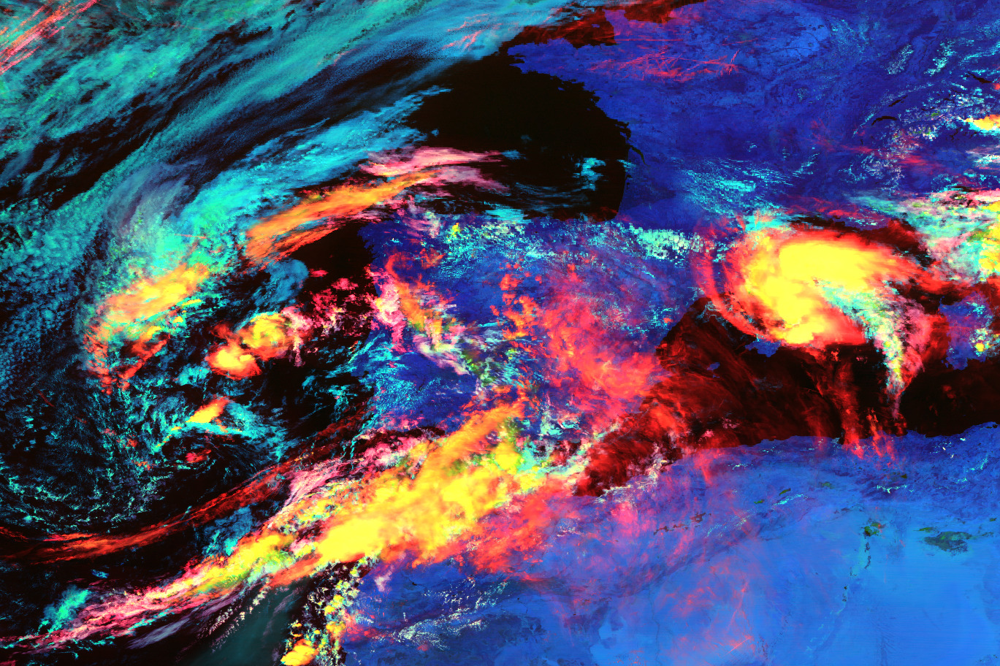

In [17]:
#exemple Espagne
coord_nord = 50
coord_sud = 30
coord_ouest = -20
coord_est = 10

!gdalwarp -q -overwrite -t_srs "EPSG:4326" -te {coord_ouest} {coord_sud} {coord_est} {coord_nord}  {filename}.tif {filename}_decoupe_HD.tif
!convert {filename}_decoupe_HD.tif {filename}_decoupe_HD.jpg

im = Image.open(filename + '_decoupe_HD.jpg')
display(im)


<div class="alert alert-info alert-success">
    
## 7 - Reprojection orthographique
</div>

### 🗺️ Projection orthographique centrée sur une latitude/longitude donnée

Cette projection donne l’impression de voir la Terre depuis l’espace.

🌍 Projection orthographique : cimss_cloud_type


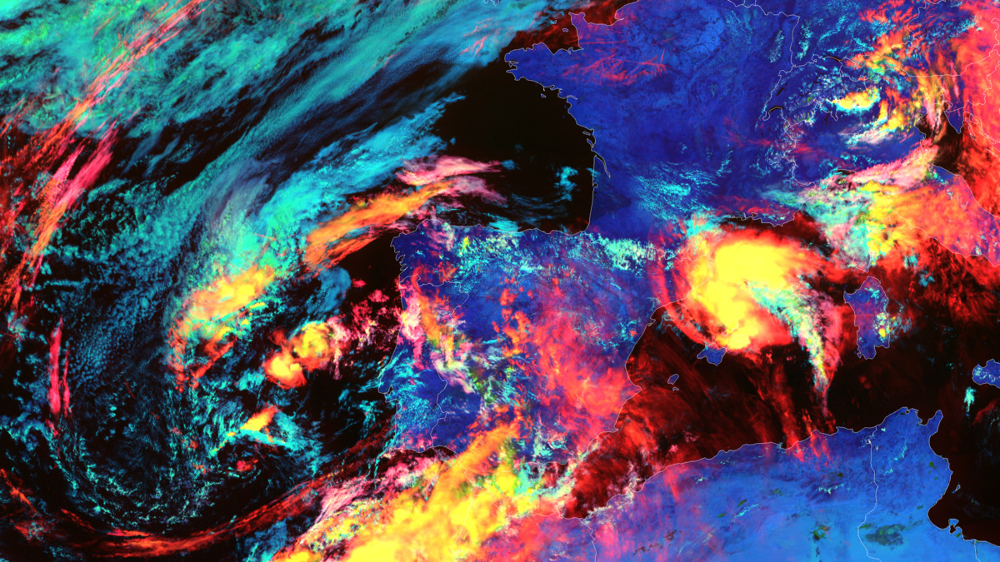

In [18]:
center_lat, center_lon = 42, -5   # Centre sur l’Espagne

# Projection orthographique avec dimensions 3200x1800 pixels
!gdalwarp -q -overwrite -t_srs "+proj=ortho +lat_0={center_lat} +lon_0={center_lon}" \
          -ts 3200 1800 -te -1600000 -900000 1600000 900000 \
          {filename}.tif {filename}_decoupe_ortho.tif 2>/dev/null

!gdal_rasterize -q -b 1 -burn 255 -b 2 -burn 255 -b 3 -burn 255 \
          -l world-administrative-boundaries OUTILS/boundary/world-administrative-boundaries.shp \
          {filename}_decoupe_ortho.tif >/dev/null 2>&1 # frontière rouge

!convert -resize 1200 {filename}_decoupe_ortho.tif {filename}_decoupe_ortho.jpg 2>/dev/null

print(f"🌍 Projection orthographique : {composite_name}")

im = Image.open(filename + '_decoupe_ortho.jpg')
display(im)

### <div style='background-color: #872459; color: white; padding: 10px; border-radius: 12px; text-align: left;'> ✏️ Exercice</div>

### Créer un autre produit composite et découper sur la zone de votre choix

### -> Utiliser le Notebook : I - 🌍🛰️Satpy : Notebook pour exercice 

---

## ✅ Récapitulatif des commandes essentielles

| Action | Commande Satpy / GDAL |
|--------|----------------------|
| Charger une scène | `Scene(filenames=..., reader=...)` |
| Lister les composites | `scn.available_composite_names()` |
| Générer un composite | `scn.load(['composite_name'])` |
| Ré-échantillonner | `scn.resample(area, resampler='nearest')` |
| Sauvegarder en GeoTIFF | `scn.save_dataset('comp', filename)` |
| Découper avec GDAL | `gdalwarp -te xmin ymin xmax ymax ...` |
| Reprojection ortho | `gdalwarp -t_srs "+proj=ortho +lat_0=... +lon_0=..."` |

---

## 🔗 Ressources complémentaires

- [Documentation Satpy](https://satpy.readthedocs.io)

---

✅ **Fin du TP**